# Notebook 02 - 2026 carboplatin scoring panel

**PharmaShield GCC** - Group 3, AI in Operations, SP Jain Dubai. Academic prototype for a hypothetical UAE GPO.

| Item | Value |
|---|---|
| Build step covered | Build step 3 - Build the 2026 oncology scoring panel |
| Key questions served | Q1 (who can we buy from), Q2 (data fusion and entity resolution), Q6 (probation fairness) |
| Inputs | openFDA NDC, Drug Shortages and Enforcement caches (14 Nov 2026); FDA Data Dashboard inspections; Medicaid State Drug Utilization Data 2025; World Bank LPI 2023 edition; notebook 01 outputs |
| Outputs | data/processed/scoring_panel_carboplatin.csv, data/processed/fda_match_table.csv, data/processed/fda_matched_inspections.csv, figures/fig_05 to fig_07 |
| Demo SKU | CARBOPLATIN_INJ_10MG_ML, carboplatin injection 10 mg/mL, Tier 1 (life-critical oncology). Not a cold-chain product. |

## 1. Objective

**Section intro.** The GPO can only buy from makers that are authorised to sell finished carboplatin injection. This notebook builds that list and attaches real 2026 evidence to every maker:
1. **Qualification filter**: keep only finished-injection, human prescription listings; drop bulk-ingredient (API) labelers (override 1).
2. **Entity resolution**: map each US labeler to the company that makes the product and to its corporate parent, using a reviewed mapping table, then match to FDA and SCMS records with rapidfuzz (override 3).
3. **Criteria inputs**: C1 price (Medicaid 2025 proxy plus a data-based freight markup), C4 compliance inputs (inspections, recalls, shortages), C5 route exposure (labelled route-mix assumption times World Bank LPI).
4. **Probation scenario**: who the GPO's current incumbents are, justified from market data (override 4).

In [1]:
import sys, json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[0]))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rapidfuzz import fuzz, process

from src.common import RAW, PROCESSED, REFERENCE, RANDOM_STATE, PALETTE, style, save_fig, shape

style()
RUN_DATE = pd.Timestamp("2026-11-14")          # data cut-off: date of every cached API pull
WINDOW_5Y = RUN_DATE - pd.DateOffset(years=5)  # plan: OAI and recalls over the past 5 years
WINDOW_3Y = RUN_DATE - pd.DateOffset(years=3)  # assumption A13: probation trial gate
SKU_ID = "CARBOPLATIN_INJ_10MG_ML"
print("Data cut-off", RUN_DATE.date(), "| 5-year window from", WINDOW_5Y.date(), "| 3-year window from", WINDOW_3Y.date())

Data cut-off 2026-11-14 | 5-year window from 2021-11-14 | 3-year window from 2023-11-14


**Section summary.** All evidence is read from dated caches in data/raw, so the panel can be rebuilt exactly. Windows are fixed relative to the 14 Nov 2026 data cut-off.

## 2. Exploratory data analysis

**Section intro.** We first look at the raw NDC listings: who appears for carboplatin, with which dosage form and marketing category. This is where the plan's "18 labelers" came from.

In [2]:
ndc_doc = json.loads((RAW / "openfda_ndc_carboplatin_20261114.json").read_text(encoding="utf-8"))
ndc = pd.DataFrame(ndc_doc["results"])
shape("openFDA NDC carboplatin listings", ndc)
listing = (ndc.groupby(["labeler_name", "dosage_form", "marketing_category", "product_type"]).size()
              .rename("listings").reset_index().sort_values(["product_type", "labeler_name"]))
print(f"Distinct labelers: {ndc['labeler_name'].nunique()}")
listing

openFDA NDC carboplatin listings: 48 rows x 19 columns
Distinct labelers: 18


,labeler_name,dosage_form,marketing_category,product_type,listings
4,Cipla Ltd.,POWDER,BULK INGREDIENT,BULK INGREDIENT,1
8,Heraeus Precious Metals GmbH & Co. KG,POWDER,BULK INGREDIENT,BULK INGREDIENT,1
9,Hetero Labs Limited,POWDER,BULK INGREDIENT,BULK INGREDIENT,1
12,"SUN PHARMACEUTICAL INDUSTRIES, INC.",POWDER,BULK INGREDIENT,BULK INGREDIENT,1
13,Sicor de Mexico S.A. de C.V,POWDER,BULK INGREDIENT,BULK INGREDIENT,1
16,Umicore Agrentina s.A.,POWDER,BULK INGREDIENT,BULK INGREDIENT,1
17,"Veranova, L.P.",POWDER,BULK INGREDIENT,BULK INGREDIENT,2
0,"AVYXA Pharma, LLC",INJECTION,NDA,HUMAN PRESCRIPTION DRUG,2
1,"Accord Healthcare, Inc.",INJECTION,ANDA,HUMAN PRESCRIPTION DRUG,1
2,Apotex Corp.,"INJECTION, SOLUTION",ANDA,HUMAN PRESCRIPTION DRUG,1


**Business interpretation.** The openFDA NDC directory lists 48 carboplatin products from 18 labelers. Seven of those labelers (including Cipla and Hetero) list only bulk powder: they sell the active ingredient to other factories, not a finished injection a hospital can use. So the plan's "18 authorised labelers" overstates the real choice for the GPO.

In [3]:
short_doc = json.loads((RAW / "openfda_shortages_carboplatin_20261114.json").read_text(encoding="utf-8"))
short = pd.DataFrame(short_doc["results"])
short["labeler_code"] = short["package_ndc"].astype(str).str.split("-").str[0].str.zfill(4)
shape("openFDA carboplatin shortage records", short)
print(short["status"].value_counts().to_string())
link = short.groupby(["company_name", "labeler_code"]).agg(records=("status", "size"),
        current=("status", lambda s: (s == "Current").sum())).reset_index()
link

openFDA carboplatin shortage records: 35 rows x 17 columns
status
Current               29
To Be Discontinued     6


,company_name,labeler_code,records,current
0,Accord Healthcare Inc.,16729,4,4
1,"Avyxa Pharma, LLC",83831,2,2
2,Eugia US LLC,55150,2,2
3,"Fresenius Kabi USA, LLC",63323,1,1
4,Gland Pharma Limited,54288,4,4
5,"Hospira, Inc., a Pfizer Company",61703,8,8
6,Ingenus Pharmaceuticals LLC,50742,2,0
7,"Teva Pharmaceuticals USA, Inc.",0703,4,4
8,Teyro Labs,60505,4,0
9,Teyro Labs,69339,4,4


**Business interpretation.** There are 35 carboplatin shortage records, 29 of them current. The shortage file reveals hidden supply links: Gland Pharma reports shortages for 4 BPI Labs products (labeler code 54288), and Teyro Labs reports shortages for Natco (69339) and Apotex (60505) products. The company on the label is often not the company that makes the drug, which matters when two "different" suppliers share one plant.

**Section summary.** The raw listings mix finished injection with bulk powder, and the shortage file names the company that makes a product, which is not always the labeler. Both facts shape the next section.

## 3. Preprocessing

### 3.1 Qualification filter (override 1)

**Section intro.** A hospital buyer can only order a finished, human prescription injection. Bulk-ingredient listings are raw material for other factories (assumption A14).

In [4]:
shape("Before qualification filter (listings)", ndc)
qualified = ndc[ndc["product_type"].eq("HUMAN PRESCRIPTION DRUG")
                & ndc["dosage_form"].str.contains("INJECTION", na=False)
                & ndc["marketing_category"].isin(["ANDA", "NDA", "BLA"])].copy()
shape("After qualification filter (listings)", qualified)
excluded = sorted(set(ndc["labeler_name"]) - set(qualified["labeler_name"]))
print(f"Qualified makers: {qualified['labeler_name'].nunique()} | Excluded bulk-ingredient labelers: {len(excluded)}")
print("Excluded:", "; ".join(excluded))

Before qualification filter (listings): 48 rows x 19 columns
After qualification filter (listings): 40 rows x 19 columns
Qualified makers: 11 | Excluded bulk-ingredient labelers: 7
Excluded: Cipla Ltd.; Heraeus Precious Metals GmbH & Co. KG; Hetero Labs Limited; SUN PHARMACEUTICAL INDUSTRIES, INC.; Sicor de Mexico S.A. de C.V; Umicore Agrentina s.A.; Veranova, L.P.


**Business interpretation.** Eleven makers qualify (40 finished-injection listings); the 7 bulk-ingredient labelers are excluded. Every later step, from scoring to the order split, uses these 11 makers only. Cipla and Hetero are not in the scoring panel.

### 3.2 Reviewed entity map: labeler, maker and parent (override 3)

**Section intro.** The NDC labeler is the company on the US label. The plant may belong to another company, and the corporate parent may appear in other data under its own name. The table below was reviewed by hand; each row states its evidence. Two links come straight from the shortage data (BPI Labs products are listed under Gland Pharma; Natco products are listed under Teyro Labs).

In [5]:
entity = pd.read_csv(REFERENCE / "maker_entity_map.csv", dtype=str).fillna("")
shape("Reviewed entity map", entity)
code_to_maker = {c: row.maker_id for row in entity.itertuples() for c in row.labeler_codes.split(";")}
qualified["labeler_code"] = qualified["product_ndc"].str.split("-").str[0].str.zfill(4)
qualified["maker_id"] = qualified["labeler_code"].map(code_to_maker)
assert qualified["maker_id"].notna().all(), "A qualified labeler code is missing from the entity map"
assert set(entity["labeler_name_fda"]) == set(qualified["labeler_name"]), "Entity map and qualified labelers differ"
entity[["maker_id", "labeler_name_fda", "labeler_codes", "parent_group", "fda_aliases"]]

Reviewed entity map: 11 rows x 7 columns


,maker_id,labeler_name_fda,labeler_codes,parent_group,fda_aliases
0,AVYXA,"AVYXA Pharma, LLC",83831,Avyxa Pharma (privately held),Avyxa Pharma
1,ACCORD,"Accord Healthcare, Inc.",16729,Intas Pharmaceuticals,Accord Healthcare;Intas Pharmaceuticals
2,APOTEX,Apotex Corp.,60505,Apotex,Apotex;Apotex Research
3,BPI,BPI Labs LLC,54288,BPI Labs,BPI Labs;Gland Pharma
4,EUGIA,Eugia US LLC,55150,Aurobindo Pharma,Eugia Pharma Specialities;Eugia SEZ;Eugia US
5,FRESENIUS,"Fresenius Kabi USA, LLC",63323,Fresenius SE,Fresenius Kabi USA;Fresenius Kabi Oncology
6,GLAND,Gland Pharma Limited,68083,Gland Pharma (Fosun Pharma majority owner),Gland Pharma
7,HOSPIRA,"Hospira, Inc.",61703,Pfizer,Hospira;Hospira Worldwide;Zydus Hospira Oncology
8,NATCO,Natco Pharma USA LLC,69339,Natco Pharma,Natco Pharma
9,TEVA,"Teva Parenteral Medicines, Inc.",0703,Teva Pharmaceutical Industries,Teva Parenteral Medicines


**Business interpretation.** Every maker now has a reviewed link from US labeler to plant owner and corporate parent, with the evidence written down: for example Eugia to Aurobindo, Hospira to Pfizer, Accord to Intas, and BPI Labs to its contract maker Gland Pharma. This is what lets one supplier's FDA, recall and shipment records be joined into a single risk profile.

### 3.3 Fuzzy matching to FDA inspection records (rapidfuzz)

**Section intro.** FDA spells firm names many ways ("EUGIA Pharma Specialities Limited", "Eugia Pharma Specialities Limited"). We normalise legal suffixes, then score every drug-inspection firm name against each maker's aliases with `token_sort_ratio`. The plan's rule was "score of 88 or more". On its own that rule is unsafe here: generic words such as "Pharmaceuticals" carry most of the score, so "Ionis Pharmaceuticals" scores 90.5 against "Intas Pharmaceuticals". We add a second test: the distinctive first word of the name (Intas, Eugia, Hospira) must itself score 90 or more. The full candidate table, including every rejection and its reason, is saved for manual review. We also show why a plain text search is unsafe.

In [6]:
insp_raw = pd.read_excel(RAW / "fda_dashboard_inspections_20261114.xlsx")
shape("FDA inspections (all product types)", insp_raw)
insp = insp_raw[insp_raw["Product Type"].eq("Drugs")].copy()
shape("FDA inspections (drugs only)", insp)

SUFFIXES = {"inc", "llc", "ltd", "limited", "private", "pvt", "corp", "corporation", "co", "company", "sa", "de", "cv",
            "gmbh", "srl", "plc", "the", "kg", "ag", "spa", "bv", "pty"}

def normalise(name):
    tokens = "".join(ch.lower() if ch.isalnum() else " " for ch in str(name)).split()
    return " ".join(t for t in tokens if t not in SUFFIXES)

names = pd.Series(insp["Legal Name"].dropna().unique())
norm_names = names.map(normalise)
rows = []
for m in entity.itertuples():
    for alias in m.fda_aliases.split(";"):
        hits = process.extract(normalise(alias), norm_names.tolist(), scorer=fuzz.token_sort_ratio, limit=8, score_cutoff=75)
        key = normalise(alias).split()[0]
        for _, score, idx in hits:
            key_score = fuzz.ratio(key, norm_names.iloc[idx].split()[0]) if norm_names.iloc[idx] else 0
            if score < 88:
                decision = "reject (below 88)"
            elif key_score < 90:
                decision = "reject (distinctive name differs)"
            else:
                decision = "accept"
            rows.append({"maker_id": m.maker_id, "alias": alias, "fda_legal_name": names.iloc[idx], "score": round(score, 1),
                         "distinctive_name_score": round(key_score, 1), "decision": decision})
match_table = pd.DataFrame(rows).drop_duplicates(["maker_id", "fda_legal_name"]).sort_values(["maker_id", "score"], ascending=[True, False])
match_table.to_csv(PROCESSED / "fda_match_table.csv", index=False)
print(match_table["decision"].value_counts().to_string())
match_table

FDA inspections (all product types): 345,856 rows x 15 columns
FDA inspections (drugs only): 40,549 rows x 15 columns


decision
reject (below 88)                    46
accept                               25
reject (distinctive name differs)     7


,maker_id,alias,fda_legal_name,score,distinctive_name_score,decision
8,ACCORD,Accord Healthcare,"Accord Healthcare, Inc.",100.0,100.0,accept
16,ACCORD,Intas Pharmaceuticals,Intas Pharmaceuticals Ltd.,100.0,100.0,accept
17,ACCORD,Intas Pharmaceuticals,Intas Pharmaceuticals Limited,100.0,100.0,accept
18,ACCORD,Intas Pharmaceuticals,Inga Pharmaceuticals,92.7,66.7,reject (distinctive name differs)
9,ACCORD,Accord Healthcare,"Corad Healthcare, Inc.",90.9,72.7,reject (distinctive name differs)
19,ACCORD,Intas Pharmaceuticals,"Ionis Pharmaceuticals, Inc.",90.5,60.0,reject (distinctive name differs)
20,ACCORD,Intas Pharmaceuticals,Ionis Pharmaceuticals Inc.,90.5,60.0,reject (distinctive name differs)
21,ACCORD,Intas Pharmaceuticals,"Atlas Pharmaceuticals, LLC",90.5,60.0,reject (distinctive name differs)
22,ACCORD,Intas Pharmaceuticals,NPS Pharmaceuticals Inc.,90.0,50.0,reject (distinctive name differs)
23,ACCORD,Intas Pharmaceuticals,"Intermax Pharmaceuticals, Inc.",88.9,61.5,reject (distinctive name differs)


**Business interpretation.** Of 78 candidate name pairs, 25 were accepted, 46 scored below 88 and 7 were rejected by the distinctive-name test. All 7 of those false matches would have been accepted under the plan's single 88 threshold, and all 7 would have attached other firms' inspections to Accord (for example Ionis and Atlas Pharmaceuticals). For the GPO, a wrong match means blaming a supplier for someone else's failed inspection, so the review table is saved in data/processed/fda_match_table.csv.

In [7]:
naive = insp[insp["Legal Name"].str.lower().str.contains("gland", na=False)]["Legal Name"].value_counts()
accepted_gland = set(match_table.query("maker_id == 'GLAND' and decision == 'accept'")["fda_legal_name"])
naive_table = naive.rename("inspections").to_frame()
naive_table["fuzzy_decision"] = ["accept" if n in accepted_gland else "reject" for n in naive_table.index]
naive_table

,inspections,fuzzy_decision
Legal Name,,
Gland Pharma Limited,23,accept
Gland Chemicals Private Limited,10,reject
"Lyophilization Services of New England, Inc.",8,reject
Gland Chemicals Pvt Ltd.,3,reject
"New England Life Care, Inc.",3,reject
New England IRB,3,reject
Trinity Health - New England IRB,2,reject
New England Research Institutes,2,reject
Veteran's IRB of Northern New England,1,reject


**Business interpretation.** A plain text search for "gland" returns 13 firm names, but only 1 is Gland Pharma's finished-dose company. The other 12 (36 inspections) are mostly New England firms and an API sister company. Fuzzy matching with a review step keeps the 23 real Gland Pharma inspections and rejects the rest.

In [8]:
accepted = match_table[match_table["decision"].eq("accept")][["maker_id", "fda_legal_name"]]
shape("Inspections before linking to makers", insp)
linked = insp.merge(accepted, left_on="Legal Name", right_on="fda_legal_name", how="inner")
shape("Inspections linked to a carboplatin maker", linked)
linked["cls"] = linked["Classification"].str.extract(r"\((\w+)\)")[0]
linked[["maker_id", "FEI Number", "Legal Name", "Country/Area", "Inspection ID", "Inspection End Date", "cls"]].to_csv(
    PROCESSED / "fda_matched_inspections.csv", index=False)
recent = linked[linked["Inspection End Date"] >= WINDOW_5Y]
insp_summary = linked.groupby("maker_id").agg(inspections_all=("Inspection ID", "size"),
                                              plant_country=("Country/Area", lambda s: s.value_counts().index[0]))
insp_5y = recent.groupby("maker_id").agg(inspections_5yr=("Inspection ID", "size"),
                                         oai_count_5yr=("cls", lambda s: int((s == "OAI").sum())),
                                         vai_count_5yr=("cls", lambda s: int((s == "VAI").sum())),
                                         last_inspection=("Inspection End Date", "max"))
oai_3y = linked[(linked["Inspection End Date"] >= WINDOW_3Y) & linked["cls"].eq("OAI")].groupby("maker_id").size().rename("oai_count_3yr")
insp_features = entity[["maker_id"]].set_index("maker_id").join([insp_summary, insp_5y, oai_3y])
for col in ["inspections_all", "inspections_5yr", "oai_count_5yr", "vai_count_5yr", "oai_count_3yr"]:
    insp_features[col] = insp_features[col].fillna(0).astype(int)
insp_features

Inspections before linking to makers: 40,549 rows x 15 columns
Inspections linked to a carboplatin maker: 286 rows x 17 columns


,inspections_all,plant_country,inspections_5yr,oai_count_5yr,vai_count_5yr,last_inspection,oai_count_3yr
maker_id,,,,,,,
AVYXA,0,NaN,0,0,0,NaT,0
ACCORD,25,India,3,2,0,2025-09-16,1
APOTEX,50,Canada,14,1,5,2026-09-25,1
BPI,27,India,10,0,6,2025-04-23,0
EUGIA,17,India,7,4,2,2026-02-06,4
FRESENIUS,61,United States,8,2,4,2026-02-13,0
GLAND,23,India,6,0,3,2024-07-25,0
HOSPIRA,53,United States,5,0,2,2025-12-16,0
NATCO,18,India,5,0,4,2025-11-21,0


**Business interpretation.** We linked 286 FDA drug inspections to the 11 makers. In the last 5 years, Eugia has 4 Official Action Indicated (OAI) inspections, Accord and Fresenius Kabi 2 each, and Apotex 1; the other 7 makers have none. AVYXA has no FDA inspection on file and Teva Parenteral Medicines has none in the last 5 years, so for them a zero means no recent evidence, not a proven clean record.

### 3.4 SCMS overlap after parent mapping

**Section intro.** We look for each maker's corporate parent in the SCMS manufacturing sites and vendors. This is the real overlap between the training layer and the 2026 panel (override 3).

In [9]:
scms = pd.read_csv(PROCESSED / "scms_clean.csv")
shape("SCMS clean lines", scms)
overlap = []
for m in entity.itertuples():
    keys = [k for k in [m.scms_parent_key] if k] + [a.split()[0] for a in m.fda_aliases.split(";")]
    keys = sorted(set(k for k in keys if len(k) >= 4))
    mask = np.zeros(len(scms), dtype=bool)
    for k in keys:
        pattern = rf"\b{k}\b"
        mask |= scms["Manufacturing Site"].str.contains(pattern, case=False, regex=True) | scms["Vendor"].str.contains(pattern, case=False, regex=True)
    overlap.append({"maker_id": m.maker_id, "search_keys": ", ".join(keys), "scms_lines": int(mask.sum()),
                    "scms_sites": "; ".join(sorted(scms.loc[mask, "Manufacturing Site"].unique()))})
overlap = pd.DataFrame(overlap).set_index("maker_id")
overlap.loc[overlap.index == "BPI", ["scms_lines", "scms_sites"]] = [0, ""]  # Gland is BPI's contract maker, not its parent: no SCMS history is inherited
print(f"Makers with any SCMS history after parent mapping: {(overlap.scms_lines > 0).sum()} of {len(overlap)}")
overlap

SCMS clean lines: 10,324 rows x 34 columns


Makers with any SCMS history after parent mapping: 2 of 11


,search_keys,scms_lines,scms_sites
maker_id,,,
AVYXA,Avyxa,0,
ACCORD,"Accord, Intas",0,
APOTEX,Apotex,0,
BPI,Gland,0,
EUGIA,"Aurobindo, Eugia",3283,"Aurobindo Unit III, India; Aurobindo Unit VII, IN"
FRESENIUS,Fresenius,0,
GLAND,Gland,2,"Gland Pharma Ltd Pally Factory; Gland Pharma, Hyderabad, IN"
HOSPIRA,"Hospira, Zydus",0,
NATCO,Natco,0,


**Business interpretation.** After parent mapping, 2 of the 11 makers have SCMS history: Eugia through its parent Aurobindo (3,283 lines from two Aurobindo plants) and Gland Pharma (2 lines). This is the real overlap, and it is small. The delivery model therefore scores every maker from features (plant country, mode, freight profile), not from a supplier lookup, and only these two get a supplier-specific site prior.

**Section summary.** Eleven makers qualify. Each one now has a reviewed link to its plant owner and parent, an FDA inspection history from fuzzy matching with a visible review table, and a real count of SCMS history.

## 4. Criteria inputs for the 2026 panel

### 4.1 C1 landed cost: Medicaid 2025 price plus a data-based freight markup (assumption A4)

**Section intro.** No public GCC tender prices exist by maker. We use what US Medicaid paid per unit in 2025 for each labeler code (national totals, non-suppressed rows) as a relative price signal. Landed cost per vial = price per mL x 45 mL (the 450 mg/45 mL vial, assumption A21) x (1 + origin freight ratio + origin insurance ratio). The markups are the SCMS medians for air lines from the same origin country (notebook 01). Makers with no Medicaid rows receive the median price and are flagged `c1_imputed` (override 6).

In [10]:
med_doc = json.loads((RAW / "medicaid_sdud2025_carboplatin_20261114.json").read_text(encoding="utf-8"))
med = pd.DataFrame(med_doc["results"])
shape("Medicaid SDUD 2025 carboplatin rows", med)
for c in ["units_reimbursed", "total_amount_reimbursed", "number_of_prescriptions"]:
    med[c] = pd.to_numeric(med[c], errors="coerce")
med = med[med["suppression_used"].eq("false")].copy()
shape("After removing suppressed rows", med)
med["labeler_code"] = med["labeler_code"].str.lstrip("0").str.zfill(4)
price = med.groupby("labeler_code").agg(units_2025=("units_reimbursed", "sum"), usd_2025=("total_amount_reimbursed", "sum"))
price["price_per_ml_usd"] = price["usd_2025"] / price["units_2025"]
price["maker_id"] = price.index.map(code_to_maker)
not_qualified = price[price["maker_id"].isna()]
print("Labeler codes with Medicaid rows but not in the qualified panel:", not_qualified.index.tolist(), "(50742 = Ingenus, listed only in the shortage file as To Be Discontinued)")
price = price.dropna(subset=["maker_id"]).set_index("maker_id")
price["unit_share_2025"] = price["units_2025"] / price["units_2025"].sum()
price.sort_values("units_2025", ascending=False).round(4)

Medicaid SDUD 2025 carboplatin rows: 225 rows x 15 columns
After removing suppressed rows: 174 rows x 15 columns
Labeler codes with Medicaid rows but not in the qualified panel: ['50742'] (50742 = Ingenus, listed only in the shortage file as To Be Discontinued)


,units_2025,usd_2025,price_per_ml_usd,unit_share_2025
maker_id,,,,
HOSPIRA,754558.706,3586345.16,4.7529,0.3796
TEVA,448147.855,1335770.29,2.9806,0.2255
EUGIA,338948.296,1500313.07,4.4264,0.1705
FRESENIUS,216121.040,699645.42,3.2373,0.1087
ACCORD,195166.670,485200.38,2.4861,0.0982
APOTEX,34687.300,250390.80,7.2185,0.0175


**Business interpretation.** US Medicaid paid for 1.99 million mL of carboplatin from the 11 makers in 2025 (174 non-suppressed national rows). Hospira holds 38.0% of units, Teva 22.6%, Eugia 17.1%, Fresenius Kabi 10.9% and Accord 9.8%; Apotex has 1.7%. Price per mL ranges from 2.49 USD (Accord) to 7.22 USD (Apotex). Ingenus (code 50742) has Medicaid rows but no current finished-injection listing, so it is excluded.

In [11]:
air = scms[scms["shipment_mode"].isin(["Air", "Air Charter"])]
markup = air.groupby("origin_country").agg(air_lines=("ID", "size"), freight_ratio=("freight_to_value", "median"),
                                           insurance_ratio=("insurance_to_value", "median"))
plant_country = insp_features["plant_country"].copy()
plant_country = plant_country.fillna("United States")  # ASSUMPTION A22: no FDA inspection on file, so the labeler's home country is used
VIAL_ML = 45  # ASSUMPTION A21: the order unit is the 450 mg / 45 mL vial
c1 = pd.DataFrame({"plant_country": plant_country})
c1 = c1.join(price[["price_per_ml_usd", "units_2025", "unit_share_2025"]])
c1["c1_imputed"] = c1["price_per_ml_usd"].isna()
median_price = c1.loc[~c1["c1_imputed"], "price_per_ml_usd"].median()
c1["price_per_ml_usd"] = c1["price_per_ml_usd"].fillna(median_price)
c1 = c1.join(markup[["freight_ratio", "insurance_ratio"]], on="plant_country")
c1["landed_cost_per_vial_usd"] = c1["price_per_ml_usd"] * VIAL_ML * (1 + c1["freight_ratio"] + c1["insurance_ratio"])
print(f"Median observed price used for imputation: {median_price:.4f} USD per mL")
print(markup.loc[sorted(c1['plant_country'].unique())].round(4).to_string())
c1.sort_values("landed_cost_per_vial_usd").round(4)

Median observed price used for imputation: 3.8318 USD per mL
                air_lines  freight_ratio  insurance_ratio
origin_country                                           
Canada                 26         0.0136           0.0020
India                4212         0.0923           0.0016
United States         174         0.0999           0.0016


,plant_country,price_per_ml_usd,units_2025,unit_share_2025,c1_imputed,freight_ratio,insurance_ratio,landed_cost_per_vial_usd
maker_id,,,,,,,,
ACCORD,India,2.4861,195166.670,0.0982,False,0.0923,0.0016,122.3758
TEVA,United States,2.9806,448147.855,0.2255,False,0.0999,0.0016,147.7380
FRESENIUS,United States,3.2373,216121.040,0.1087,False,0.0999,0.0016,160.4585
GLAND,India,3.8318,NaN,NaN,True,0.0923,0.0016,188.6194
NATCO,India,3.8318,NaN,NaN,True,0.0923,0.0016,188.6194
TEYRO,India,3.8318,NaN,NaN,True,0.0923,0.0016,188.6194
BPI,India,3.8318,NaN,NaN,True,0.0923,0.0016,188.6194
AVYXA,United States,3.8318,NaN,NaN,True,0.0999,0.0016,189.9276
EUGIA,India,4.4264,338948.296,0.1705,False,0.0923,0.0016,217.8856


**Business interpretation.** Accord has the lowest estimated landed cost at 122.38 USD per 45 mL vial and Apotex the highest at 329.88 USD. The five makers without Medicaid prices (AVYXA, BPI Labs, Gland, Natco, Teyro) receive the median price of 3.83 USD per mL and are flagged c1_imputed; the dashboard shows the flag so a buyer never reads an imputed price as a quote. The Canadian air freight median rests on only 26 SCMS lines, so Apotex's markup is less certain than India's (4,212 lines).

### 4.2 C4 inputs: recalls and active shortages

**Section intro.** Recalls come from openFDA Enforcement, searched by recalling firm (assumption A15). The plan's C4 formula counts Class I and II recalls in the past 5 years, capped at 2. Fresenius Kabi Compounding is a separate business and is removed. The active-shortage flag comes from the shortage file through the labeler code in each record's package NDC, so a shortage filed under Gland Pharma for a BPI Labs NDC counts for BPI Labs.

In [12]:
rec_doc = json.loads((RAW / "openfda_recalls_carboplatin_firms_20261114.json").read_text(encoding="utf-8"))
query_to_maker = {"AVYXA Pharma": "AVYXA", "Accord Healthcare": "ACCORD", "Apotex": "APOTEX", "BPI Labs": "BPI", "Eugia US": "EUGIA",
                  "AuroMedics (former Eugia US name)": "EUGIA", "Fresenius Kabi USA": "FRESENIUS", "Gland Pharma": "GLAND",
                  "Hospira": "HOSPIRA", "Natco Pharma": "NATCO", "Teva": "TEVA", "Sicor (Teva entity)": "TEVA", "Teyro Labs": "TEYRO"}
rec = pd.DataFrame([{"maker_id": query_to_maker[q], "firm": r.get("recalling_firm"), "cls": r.get("classification"),
                     "date": pd.to_datetime(r.get("recall_initiation_date"))} for q, v in rec_doc["queries"].items() for r in v["results"]])
shape("Recall records, all firms, 10 years", rec)
rec = rec[~rec["firm"].str.contains("Compounding", case=False)]
shape("After removing Fresenius Kabi Compounding", rec)
rec5 = rec[rec["date"] >= WINDOW_5Y]
shape("Recalls in the 5-year window", rec5)
recall_features = rec5.assign(class_i=rec5["cls"].eq("Class I"), class_i_ii=rec5["cls"].isin(["Class I", "Class II"])).groupby("maker_id").agg(
    recalls_5yr=("cls", "size"), class_i_ii_5yr=("class_i_ii", "sum"), class_i_5yr=("class_i", "sum"))
class_i_3y = rec[(rec["date"] >= WINDOW_3Y) & rec["cls"].eq("Class I")].groupby("maker_id").size().rename("class_i_3yr")
recall_features = entity[["maker_id"]].set_index("maker_id").join([recall_features, class_i_3y]).fillna(0).astype(int)
active = short[short["status"].eq("Current")].assign(maker_id=lambda d: d["labeler_code"].map(code_to_maker)).dropna(subset=["maker_id"])
recall_features["active_fda_shortage"] = recall_features.index.isin(active["maker_id"])
recall_features["current_shortage_records"] = active.groupby("maker_id").size().reindex(recall_features.index).fillna(0).astype(int)
recall_features

Recall records, all firms, 10 years: 474 rows x 4 columns
After removing Fresenius Kabi Compounding: 459 rows x 4 columns
Recalls in the 5-year window: 233 rows x 4 columns


,recalls_5yr,class_i_ii_5yr,class_i_5yr,class_i_3yr,active_fda_shortage,current_shortage_records
maker_id,,,,,,
AVYXA,0,0,0,0,True,2
ACCORD,103,101,1,0,True,4
APOTEX,20,18,0,0,False,0
BPI,0,0,0,0,True,4
EUGIA,21,18,2,1,True,2
FRESENIUS,27,26,4,3,True,1
GLAND,0,0,0,0,False,0
HOSPIRA,0,0,0,0,True,8
NATCO,2,2,0,0,True,4


**Business interpretation.** The 474 recall records shrink to 459 after removing Fresenius Kabi Compounding and to 233 in the 5-year window. Accord has 101 Class I or II recalls, Teva 46, Fresenius Kabi 26, Eugia 18 and Apotex 18; five makers have none. Eight makers have a current carboplatin shortage record, which confirms the GPO's problem: most of the supply base is already strained.

### 4.3 C5 route exposure: route-mix assumption x World Bank LPI (assumption A8)

**Section intro.** C5 = min(1, StressFactor x share of volume on the Hormuz sea lane or Gulf airspace) x (1 - LPI/5). StressFactor is 1.0 in Normal mode and 1.5 in Crisis mode. The route mix by origin country is a labelled scenario assumption (pipeline/reference/route_mix_assumptions.csv); the LPI is the World Bank 2023 edition. The Worldwide Governance Indicators (WGI) are removed from the inventory: a political-stability score for the origin country would add a second country-level penalty on top of LPI without any lane evidence (decision D7).

In [13]:
lpi_doc = json.loads((RAW / "worldbank_lpi2023edition_20261114.json").read_text(encoding="utf-8"))
lpi = pd.Series({r["country"]["value"]: r["value"] for r in lpi_doc[1] if r["value"] is not None}, name="lpi_2023")
routes = pd.read_csv(REFERENCE / "route_mix_assumptions.csv").set_index("origin_country")
routes["hormuz_air_share"] = routes["air_gulf_share"] + routes["sea_hormuz_share"]
routes = routes.join(lpi)
routes["c5_normal"] = np.minimum(1.0, 1.0 * routes["hormuz_air_share"]) * (1 - routes["lpi_2023"] / 5)
routes["c5_crisis"] = np.minimum(1.0, 1.5 * routes["hormuz_air_share"]) * (1 - routes["lpi_2023"] / 5)
routes[["air_gulf_share", "sea_hormuz_share", "sea_gulf_of_oman_share", "hormuz_air_share", "lpi_2023", "c5_normal", "c5_crisis"]].round(4)

,air_gulf_share,sea_hormuz_share,sea_gulf_of_oman_share,hormuz_air_share,lpi_2023,c5_normal,c5_crisis
origin_country,,,,,,,
India,0.55,0.3,0.15,0.85,3.4,0.272,0.32
United States,0.85,0.1,0.05,0.95,3.8,0.228,0.24
Canada,0.85,0.1,0.05,0.95,4.0,0.190,0.20


**Business interpretation.** Under the stated route-mix assumption, India-made supply has the highest route exposure (C5 0.272 in Normal mode, 0.320 in Crisis mode) because its logistics score is lower (LPI 3.4) and more of its volume moves through Hormuz by sea. US-made supply scores 0.228 and 0.240, Canada-made 0.190 and 0.200. These values are scenario inputs, so the dashboard labels C5 as assumption-driven.

### 4.4 Probation scenario (override 4)

**Section intro.** The plan defined probation as "fewer than 5 SCMS shipments". That rule would put 9 of 11 makers on probation because SCMS holds ARV shipments, not oncology. Instead we define a labelled scenario (assumption A23): the GPO's current incumbents are the makers that already hold a material share of real 2026 carboplatin supply, measured by their share of 2025 Medicaid units. A threshold of 5% of units separates the panel cleanly. Everyone else is a probation candidate. A probation candidate may receive a trial order only if it passes the safety gate (assumption A13): no OAI inspection and no Class I recall in the last 3 years.

In [14]:
panel = entity[["maker_id", "labeler_name_fda", "parent_group"]].set_index("maker_id")
panel = panel.join(c1).join(insp_features.drop(columns="plant_country")).join(recall_features).join(overlap[["scms_lines"]])
panel["unit_share_2025"] = panel["unit_share_2025"].fillna(0.0)
INCUMBENT_SHARE = 0.05  # ASSUMPTION A23
panel["is_probation"] = panel["unit_share_2025"] < INCUMBENT_SHARE
panel["trial_gate_pass"] = (panel["oai_count_3yr"] == 0) & (panel["class_i_3yr"] == 0)
incumbent_cover = panel.loc[~panel["is_probation"], "unit_share_2025"].sum()
print(f"Incumbents: {(~panel.is_probation).sum()} makers covering {incumbent_cover:.1%} of 2025 Medicaid units; probation candidates: {panel.is_probation.sum()}")
print("Largest share below the threshold:", f"{panel.loc[panel.is_probation, 'unit_share_2025'].max():.1%}", "| smallest share above:", f"{panel.loc[~panel.is_probation, 'unit_share_2025'].min():.1%}")
panel[["unit_share_2025", "is_probation", "oai_count_3yr", "class_i_3yr", "trial_gate_pass"]].sort_values("unit_share_2025", ascending=False).round(4)

Incumbents: 5 makers covering 98.3% of 2025 Medicaid units; probation candidates: 6
Largest share below the threshold: 1.7% | smallest share above: 9.8%


,unit_share_2025,is_probation,oai_count_3yr,class_i_3yr,trial_gate_pass
maker_id,,,,,
HOSPIRA,0.3796,False,0,0,True
TEVA,0.2255,False,0,0,True
EUGIA,0.1705,False,4,1,False
FRESENIUS,0.1087,False,0,3,False
ACCORD,0.0982,False,1,0,False
APOTEX,0.0175,True,1,0,False
AVYXA,0.0000,True,0,0,True
GLAND,0.0000,True,0,0,True
BPI,0.0000,True,0,0,True


**Business interpretation.** Five incumbents (Hospira, Teva, Eugia, Fresenius Kabi, Accord) together hold 98.3% of 2025 Medicaid units; the gap between the smallest incumbent (9.8%) and the largest non-incumbent (1.7%) makes the 5% threshold a clean cut. The other six makers are probation candidates. Five of them pass the trial safety gate; Apotex does not, because of an OAI inspection in the last 3 years, so it cannot receive a trial order.

Saved figures\fig_05_panel_share_and_cost.png


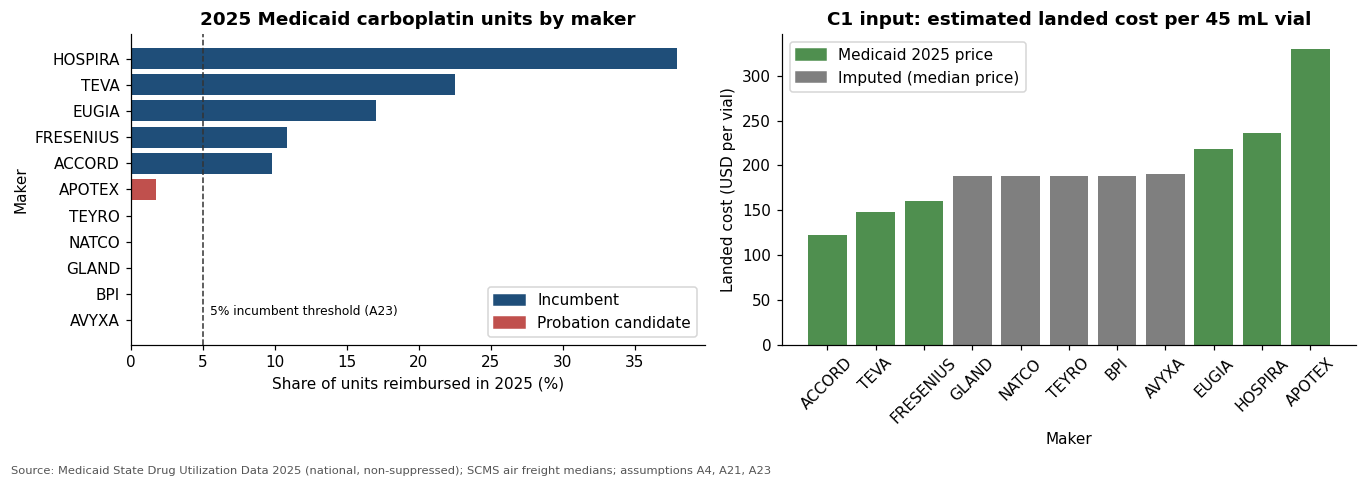

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
order = panel.sort_values("unit_share_2025", ascending=True).index
colors = [PALETTE[1] if panel.loc[m, "is_probation"] else PALETTE[0] for m in order]
axes[0].barh(order, panel.loc[order, "unit_share_2025"] * 100, color=colors)
axes[0].axvline(INCUMBENT_SHARE * 100, color="#333333", linestyle="--", linewidth=1)
axes[0].text(INCUMBENT_SHARE * 100 + 0.5, 0.2, "5% incumbent threshold (A23)", fontsize=8)
axes[0].set_title("2025 Medicaid carboplatin units by maker")
axes[0].set_xlabel("Share of units reimbursed in 2025 (%)")
axes[0].set_ylabel("Maker")
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=PALETTE[0], label="Incumbent"), Patch(color=PALETTE[1], label="Probation candidate")], loc="lower right")
order2 = panel.sort_values("landed_cost_per_vial_usd").index
colors2 = [PALETTE[6] if panel.loc[m, "c1_imputed"] else PALETTE[2] for m in order2]
axes[1].bar(order2, panel.loc[order2, "landed_cost_per_vial_usd"], color=colors2)
axes[1].set_title("C1 input: estimated landed cost per 45 mL vial")
axes[1].set_xlabel("Maker")
axes[1].set_ylabel("Landed cost (USD per vial)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(handles=[Patch(color=PALETTE[2], label="Medicaid 2025 price"), Patch(color=PALETTE[6], label="Imputed (median price)")], loc="upper left")
save_fig(fig, "fig_05_panel_share_and_cost", "Medicaid State Drug Utilization Data 2025 (national, non-suppressed); SCMS air freight medians; assumptions A4, A21, A23")
plt.show()

**Business interpretation.** The left chart shows the incumbent split the scenario rests on. The right chart shows why the price signal matters: the cheapest incumbent (Accord) costs about 52% of the most expensive incumbent (Hospira) per vial. Grey bars are imputed, which is why C1 is not used to learn entropy weights for those makers.

**Section summary.** Every maker now has C1, C4 and C5 inputs from real 2026 data or a labelled assumption, and a probation status that follows from market data rather than from an ARV dataset.

## 5. Evaluation of the panel

**Section intro.** We check the panel for completeness and print the fused 360-degree view of one maker (Q2). The C2 delivery-risk inputs (plant country, air mode, origin freight profile and the SCMS site prior) are used by the model in notebook 03.

In [16]:
panel["sku_id"] = SKU_ID
panel["criticality_tier"] = 1
panel["manufacturing_country"] = panel["plant_country"]
assert len(panel) == 11, "The panel must contain the 11 qualified makers"
assert panel["landed_cost_per_vial_usd"].notna().all()
check = pd.DataFrame({"filled": panel.notna().sum(), "missing": panel.isna().sum()})
print("Columns with missing values:")
print(check[check["missing"] > 0].to_string() if (check["missing"] > 0).any() else "none")
fused = panel.loc["EUGIA"]
print("\n360-degree view: Eugia US LLC")
print(fused.to_string())

Columns with missing values:
                 filled  missing
units_2025            6        5
last_inspection       9        2

360-degree view: Eugia US LLC
labeler_name_fda                       Eugia US LLC
parent_group                       Aurobindo Pharma
plant_country                                 India
price_per_ml_usd                           4.426377
units_2025                               338948.296
unit_share_2025                            0.170529
c1_imputed                                    False
freight_ratio                              0.092275
insurance_ratio                              0.0016
landed_cost_per_vial_usd                 217.885598
inspections_all                                  17
inspections_5yr                                   7
oai_count_5yr                                     4
vai_count_5yr                                     2
last_inspection                 2026-02-06 00:00:00
oai_count_3yr                                     4
recalls_5

**Business interpretation.** The panel has no missing criteria inputs. The only gaps are expected: Medicaid units for the five makers without Medicaid rows (their price is imputed and flagged) and the last inspection date for AVYXA (never inspected) and Teva Parenteral (no inspection in 5 years). The Eugia profile shows the data fusion working: price, FDA inspections, recalls, shortages and 3,283 SCMS lines from its parent sit in one row.

Saved figures\fig_06_panel_evidence_heatmap.png


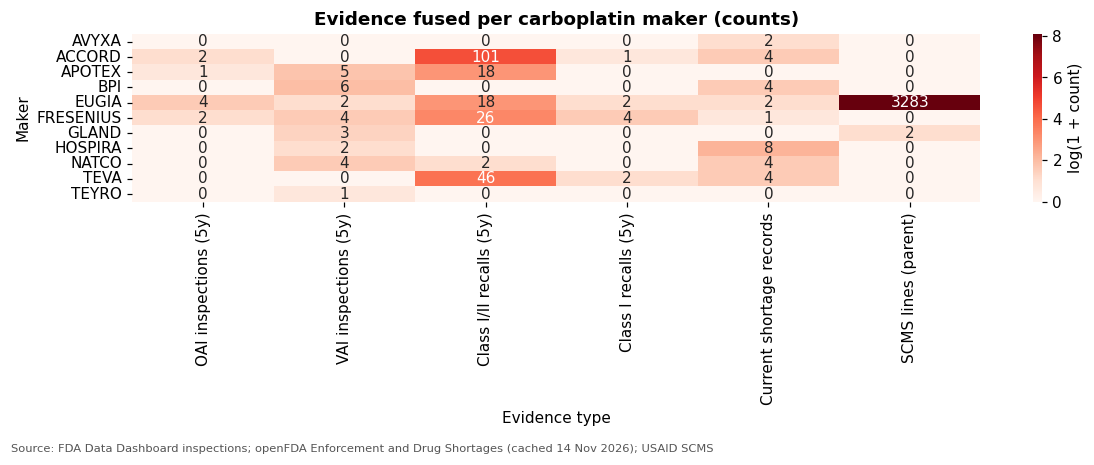

In [17]:
fig, ax = plt.subplots(figsize=(11, 4.2))
heat = panel[["oai_count_5yr", "vai_count_5yr", "class_i_ii_5yr", "class_i_5yr", "current_shortage_records", "scms_lines"]].copy()
heat.columns = ["OAI inspections (5y)", "VAI inspections (5y)", "Class I/II recalls (5y)", "Class I recalls (5y)", "Current shortage records", "SCMS lines (parent)"]
sns.heatmap(np.log1p(heat), annot=heat, fmt="d", cmap="Reds", cbar_kws={"label": "log(1 + count)"}, ax=ax)
ax.set_title("Evidence fused per carboplatin maker (counts)")
ax.set_xlabel("Evidence type")
ax.set_ylabel("Maker")
save_fig(fig, "fig_06_panel_evidence_heatmap", "FDA Data Dashboard inspections; openFDA Enforcement and Drug Shortages (cached 14 Nov 2026); USAID SCMS")
plt.show()

**Business interpretation.** Compliance evidence is concentrated: Accord carries the most recalls, Eugia the most recent OAI findings, and several probation candidates carry little or no evidence at all. This is why probation candidates get a capped trial share in the order split instead of being ranked on missing data alone.

In [18]:
out_cols = ["sku_id", "criticality_tier", "labeler_name_fda", "parent_group", "manufacturing_country", "is_probation", "trial_gate_pass",
            "unit_share_2025", "price_per_ml_usd", "c1_imputed", "freight_ratio", "insurance_ratio", "landed_cost_per_vial_usd",
            "inspections_all", "inspections_5yr", "oai_count_5yr", "vai_count_5yr", "oai_count_3yr", "last_inspection",
            "recalls_5yr", "class_i_ii_5yr", "class_i_5yr", "class_i_3yr", "active_fda_shortage", "current_shortage_records", "scms_lines"]
panel_out = panel[out_cols].join(routes[["hormuz_air_share", "lpi_2023", "c5_normal", "c5_crisis"]], on="manufacturing_country")
panel_out.index.name = "manufacturer_id"
panel_out.to_csv(PROCESSED / "scoring_panel_carboplatin.csv")
shape("Saved data/processed/scoring_panel_carboplatin.csv", panel_out)
panel_out[["manufacturing_country", "is_probation", "c1_imputed", "landed_cost_per_vial_usd", "oai_count_5yr", "class_i_ii_5yr", "active_fda_shortage", "c5_normal", "c5_crisis"]].round(3)

Saved data/processed/scoring_panel_carboplatin.csv: 11 rows x 30 columns


,manufacturing_country,is_probation,c1_imputed,landed_cost_per_vial_usd,oai_count_5yr,class_i_ii_5yr,active_fda_shortage,c5_normal,c5_crisis
manufacturer_id,,,,,,,,,
AVYXA,United States,True,True,189.928,0,0,True,0.228,0.24
ACCORD,India,False,False,122.376,2,101,True,0.272,0.32
APOTEX,Canada,True,False,329.881,1,18,False,0.190,0.20
BPI,India,True,True,188.619,0,0,True,0.272,0.32
EUGIA,India,False,False,217.886,4,18,True,0.272,0.32
FRESENIUS,United States,False,False,160.459,2,26,True,0.228,0.24
GLAND,India,True,True,188.619,0,0,False,0.272,0.32
HOSPIRA,United States,False,False,235.581,0,0,True,0.228,0.24
NATCO,India,True,True,188.619,0,2,True,0.272,0.32


**Business interpretation.** The 11-maker panel is saved with 30 columns. C2 (delivery risk), C3 (price integrity) and the NLP part of C4 are added in notebook 03, and notebook 04 turns all inputs into the final 0 to 1 criteria.

**Section summary.** The panel is complete for 11 makers with no missing criteria inputs. Two values are imputed or assumed and are flagged in the data: C1 for makers without Medicaid rows, and the plant country for the one maker with no FDA inspection on file.

## 6. Conclusion

**Recommendation.** Score exactly 11 qualified makers of carboplatin injection 10 mg/mL. Use a reviewed entity map and two-test fuzzy matching for every external data join. Treat the 5 incumbents (98.3% of 2025 units) as established suppliers and the 6 others as probation candidates. Only the 5 that pass the safety gate may receive a trial order.

**Numbers that the deck should use from this notebook.**
- 11 qualified makers (7 bulk-ingredient labelers excluded).
- 2 of 11 makers with SCMS history after parent mapping.
- 7 false name matches prevented by the second matching test.
- Landed cost from 122.38 to 329.88 USD per vial.
- 8 of 11 makers with a current US shortage record.

**Limits.** Medicaid prices are a US proxy for GCC tender prices (A4). Plant country is the most frequent inspected country of the maker's entities, not the confirmed plant for this exact product (A22). The route mix is a scenario assumption (A8).

**Future improvements.**
- Replace the Medicaid proxy with the GPO's own tender quotes.
- Confirm each product's plant from the label or the Drug Master File.
- Add the Emirates Drug Establishment (EDE) registration status as the true UAE qualification gate.
- Re-run the fuzzy match review whenever the FDA files are refreshed.

**End of notebook 02.** Next: notebook 03 trains the delivery-risk, anomaly and NLP models.